# Do the general seed rules still work on graphs with communities?

Round 1 found rules that pick better seeds than random on ER, PAPER and Chung–Lu graphs. For example, seeds whose neighbourhoods overlap help percolation, and seeds that tell vertices apart help GOAT. This notebook asks whether the same rules still beat random on stochastic block models (SBMs), where the vertices form communities.

The pooled score's weights never saw communities, so this is a test of the general rules, not of the learned weights. SBM's own weights come from `sbm_models.ipynb`.

**Graphs.** Each kind of SBM is matched to a round-1 model, so that communities are the only change:

| Setting | What it is | Matched round-1 model | Mean degree | ρ | GOAT regulariser |
|---|---|---|---|---|---|
| SBM | 4 equal blocks of 150 vertices, 80% of edges inside blocks, otherwise ER | ER | 12 (percolation), 16 (GOAT, FAQ) | 0.70 (percolation), 0.50 (GOAT, FAQ) | 100 |
| Degree-corrected SBM | The same blocks on Chung–Lu weights (Pareto shape 2) | Chung–Lu | 12 (percolation), 16 (GOAT, FAQ) | 0.70 (percolation), 0.45 (GOAT, FAQ) | 300 |

**Budgets.** Communities may change how many seeds a random set needs. Each algorithm and setting is therefore calibrated first, as in part C of `score_transfer.ipynb`. On 10 separate calibration pairs, 3 random sets per pair (30 per budget) are run once each along a budget ladder. The ladder starts at the matched model's training budget. k50 is the budget where random sets succeed closest to half the time. The budget grid is k50 times these factors, rounded:

| Algorithm | Factors |
|---|---|
| Percolation | 0.4, 0.55, 0.7, 0.85, 1.0, 1.25 |
| GOAT | 0.4, 0.55, 0.65, 0.75, 0.9, 1.1 |
| FAQ | 0.55, 0.65, 0.75, 0.85, 0.95, 1.1 |

**Rules,** on 20 fresh pairs per setting:

| Rule | What it does |
|---|---|
| Round 1's rules | Random, top degree, clustered (pair mass), spread (coverage) and distinguishing, plus top harmonic (percolation) or hub-free distinguishing (GOAT). Same code and settings as round 1. |
| Top degree by block | Top degree spread over the blocks in proportion to their size (round robin for equal blocks), using the true block labels. Asks whether spreading seeds over communities helps. |
| Best of 1,000 | The highest pooled score among 1,000 random sets, with the ER, PAPER and Chung–Lu weights averaged. Not a fair test of the weights; shown for reference. |
| Best of 1,000 by degree | The most seed-to-nonseed edges among the same 1,000 sets: the control for best of 1,000. |
| Best of 100 and 1,000 (SBM weights) | Added later by `sbm_models.ipynb` (section 7), after SBM's own weights are fitted. They appear in this notebook's tables and figures once run. |

**Runs.** Round 1's protocol: percolation and GOAT run once, and FAQ restarts up to 3 times, stopping at the first success. Every rule meets the same solver randomness. Success means accuracy ≥ 0.5 for percolation and unseeded accuracy ≥ 0.9 for GOAT and FAQ.

**Run time:** about 1.5 hours with 3 jobs. Rerunning resumes, and the analysis works on whatever is finished.

| Section | Content |
|---|---|
| 1 | Pairs and budgets |
| 2 | Success curves |
| 3 | Mean success and queries needed |
| 4 | Against random and top degree |
| 5 | Same rules with and without communities |
| 6 | Where the seeds land |

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
if str(EXPERIMENT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR.parent))

import importlib

from selection_rule_comparison.archive import sbm_graphs as G
from selection_rule_comparison.archive import sbm_rules as SR

G = importlib.reload(G)
SR = importlib.reload(SR)   # picks up edits to sbm_rules.py without restarting the kernel

pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth', 120)

RUN_COLLECTION = True                                 # False: only analyse saved results
ALGORITHMS_TO_RUN = ['percolation', 'goat', 'faq']    # remove any to skip it
SETTINGS_TO_RUN = ['sbm', 'dcsbm']                    # later: 'sbm_unequal', 'dcsbm_unequal', 'sbm_weak', 'dcsbm_weak'
JOBS = 3                                              # tasks run in parallel

## Run

The cell below prints an estimate, then one line per finished task. Budget calibrations run first. Each calibration's line reports k50, the budget grid and the random success rate at every budget tried, and then queues its 20 pairs.

The interrupt button stops the workers too. To run in a terminal instead, from the repository root: `python -m selection_rule_comparison.sbm_rules`. Ctrl-C stops it, and `--status` shows how far it is. Then set `RUN_COLLECTION = False` here to analyse.

In [2]:
if RUN_COLLECTION:
    SR.run_all(ALGORITHMS_TO_RUN, SETTINGS_TO_RUN, jobs=JOBS)
display(SR.status(settings=SETTINGS_TO_RUN))

Everything is done. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/sbm_rules


budgets  \
algorithm   setting                                                  
Percolation SBM                         k50 = 8: 3, 4, 6, 7, 8, 10   
            degree-corrected SBM            k50 = 5: 2, 3, 4, 5, 6   
GOAT        SBM                       k50 = 12: 5, 7, 8, 9, 11, 13   
            degree-corrected SBM            k50 = 2: 2, 3, 4, 5, 6   
SGM (FAQ)   SBM                   k50 = 28: 15, 18, 21, 24, 27, 31   
            degree-corrected SBM  k50 = 19: 10, 12, 14, 16, 18, 21   

                                  pairs planned  pairs done  
algorithm   setting                                          
Percolation SBM                              20          20  
            degree-corrected SBM             20          20  
GOAT        SBM                              20          20  
            degree-corrected SBM             20          20  
SGM (FAQ)   SBM                              20          20  
            degree-corrected SBM             20          20

## 1. Pairs and budgets

- **Budgets:** k50 for each algorithm and setting, the random success rate at every budget tried (30 sets each), and the budget grid. The matched round-1 model's training budget is shown for comparison. If k50 differs a lot from it, communities changed how hard the problem is.
- **Pairs:** the test pairs' mean and largest degree, the share of edges inside blocks (about 0.80 by design) and the share of A's edges that B keeps (about ρ).

In [3]:
display(SR.calibration_table(settings=SETTINGS_TO_RUN))
runs = SR.read_runs(settings=SETTINGS_TO_RUN)
display(SR.pair_table(runs))

matched model's training budget  k50  \
algorithm   setting                                                     
Percolation SBM                                           8 (ER)    8   
            degree-corrected SBM                    5 (Chung-Lu)    5   
GOAT        SBM                                          15 (ER)   12   
            degree-corrected SBM                    9 (Chung-Lu)    2   
SGM (FAQ)   SBM                                          29 (ER)   28   
            degree-corrected SBM                   27 (Chung-Lu)   19   

                                                                 status  \
algorithm   setting                                                       
Percolation SBM                                                      ok   
            degree-corrected SBM                                     ok   
GOAT        SBM                                                      ok   
            degree-corrected SBM  above 50% at the bottom of the ladder   
SGM (FAQ)   SBM                                                      ok   
            degree-corrected SBM                                     ok   

                                           random success by budget (30 sets each)  \
algorithm   setting                                                                  
Percolation SBM                                                  8: 0.43, 10: 0.83   
            degree-corrected SBM                                  4: 0.37, 5: 0.63   
GOAT        SBM                              8: 0.07, 10: 0.30, 12: 0.57, 14: 0.63   
            degree-corrected SBM                2: 0.73, 4: 0.87, 6: 1.00, 8: 0.93   
SGM (FAQ)   SBM                                       24: 0.07, 26: 0.27, 28: 0.57   
            degree-corrected SBM  18: 0.30, 19: 0.43, 21: 0.67, 24: 0.90, 28: 0.97   

                                             budget grid  
algorithm   setting                                       
Percolation SBM                        3, 4, 6, 7, 8, 10  
            degree-corrected SBM           2, 3, 4, 5, 6  
GOAT        SBM                       5, 7, 8, 9, 11, 13  
            degree-corrected SBM           2, 3, 4, 5, 6  
SGM (FAQ)   SBM                   15, 18, 21, 24, 27, 31  
            degree-corrected SBM  10, 12, 14, 16, 18, 21

pairs  mean_degree  largest_degree  \
algorithm   setting                                                    
Percolation SBM                      20        12.02           23.65   
            degree-corrected SBM     20        12.03           87.50   
GOAT        SBM                      20        16.11           29.55   
            degree-corrected SBM     20        16.01           97.45   
SGM (FAQ)   SBM                      20        16.11           29.55   
            degree-corrected SBM     20        16.01           97.45   

                                  share_inside_blocks  edges_kept_in_B  
algorithm   setting                                                     
Percolation SBM                                   0.8             0.72  
            degree-corrected SBM                  0.8             0.73  
GOAT        SBM                                   0.8             0.54  
            degree-corrected SBM                  0.8             0.51  
SGM (FAQ)   SBM                                   0.8             0.54  
            degree-corrected SBM                  0.8             0.51

## 2. Success curves

The share of the 20 pairs where each rule succeeds, against the budget.
- **Rows:** algorithms. **Columns:** settings.
- **Grey:** random. **Black:** top degree; dashed with open squares, top degree by block.
- **Orange:** round 1's other rules, one shape each.
- **Dark blue:** best of 1,000 by the averaged score. **Aqua:** best of 1,000 by degree.
- **Dashed blue, open diamonds:** best of 100 and 1,000 by SBM's own weights, once `sbm_models.ipynb` has run them.

A rule above the grey line beats random at that budget. k50 is in each title.

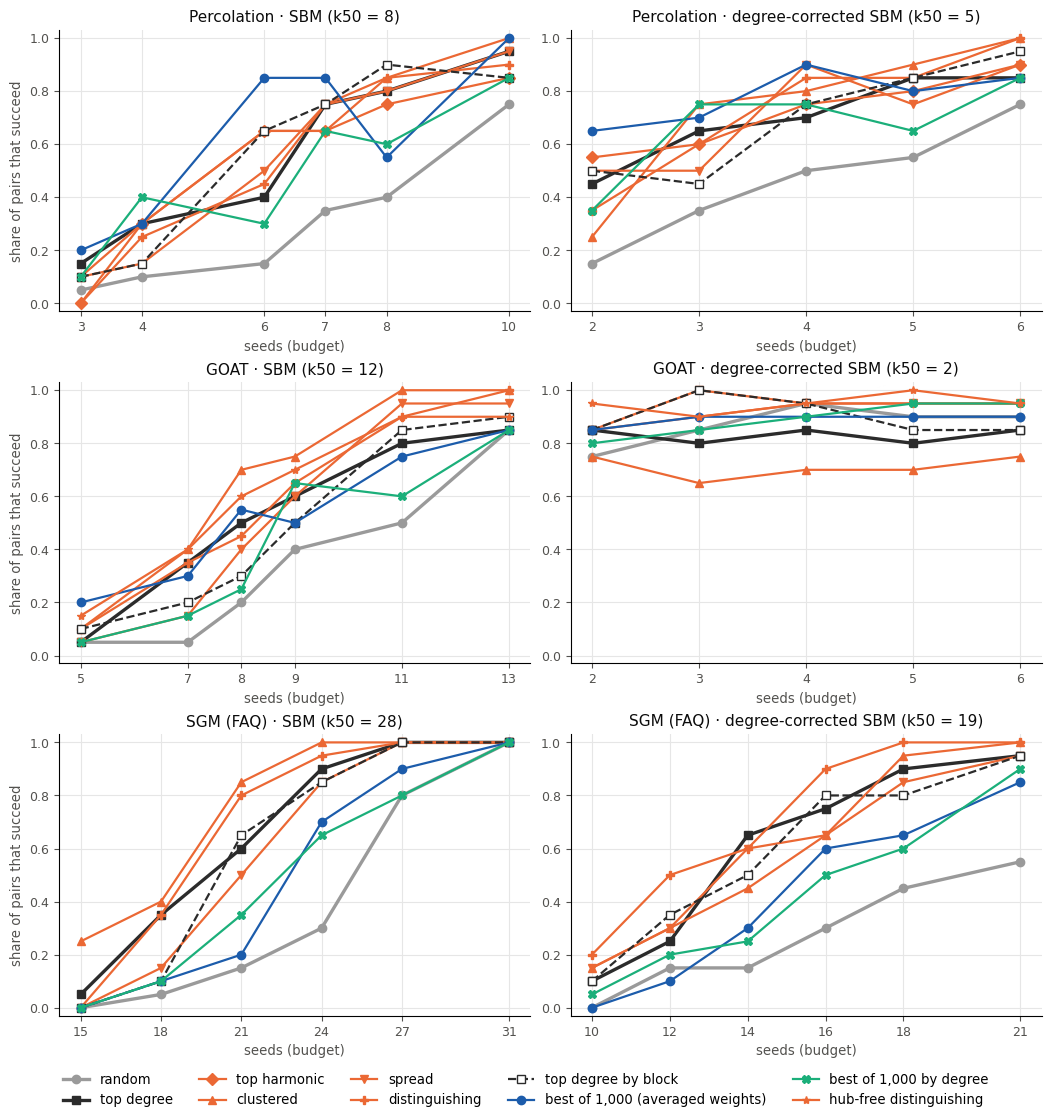

In [4]:
ev = SR.load_evaluations(settings=SETTINGS_TO_RUN)
curves = SR.success_curves(ev)
SR.plot_success_curves(curves)
plt.show()

## 3. Mean success and queries needed

- **Mean success over budgets:** each pair's success rate over the budget grid, averaged over pairs.
- **Mean queries needed:** the smallest budget at which the rule succeeds on the pair. A pair where the rule never succeeds counts as one grid step past the largest budget.

The intervals are 95% bootstrap intervals over pairs.

In [5]:
queries = SR.queries_needed(ev)
display(SR.summary_table(ev, queries))

pairs  \
algorithm   setting              rule                                      
Percolation SBM                  random                               20   
                                 top degree                           20   
                                 top harmonic                         20   
                                 clustered                            20   
                                 spread                               20   
                                 distinguishing                       20   
                                 top degree by block                  20   
                                 best of 1,000 (averaged weights)     20   
                                 best of 1,000 by degree              20   
            degree-corrected SBM random                               20   
                                 top degree                           20   
                                 top harmonic                         20   
                                 clustered                            20   
                                 spread                               20   
                                 distinguishing                       20   
                                 top degree by block                  20   
                                 best of 1,000 (averaged weights)     20   
                                 best of 1,000 by degree              20   
GOAT        SBM                  random                               20   
                                 top degree                           20   
                                 clustered                            20   
                                 spread                               20   
                                 distinguishing                       20   
                                 top degree by block                  20   
                                 best of 1,000 (averaged weights)     20   
                                 best of 1,000 by degree              20   
                                 hub-free distinguishing              20   
            degree-corrected SBM random                               20   
                                 top degree                           20   
                                 clustered                            20   
                                 spread                               20   
                                 distinguishing                       20   
                                 top degree by block                  20   
                                 best of 1,000 (averaged weights)     20   
                                 best of 1,000 by degree              20   
                                 hub-free distinguishing              20   
SGM (FAQ)   SBM                  random                               20   
                                 top degree                           20   
                                 clustered                            20   
                                 spread                               20   
                                 distinguishing                       20   
                                 top degree by block                  20   
                                 best of 1,000 (averaged weights)     20   
                                 best of 1,000 by degree              20   
            degree-corrected SBM random                               20   
                                 top degree                           20   
                                 clustered                            20   
                                 spread                               20   
                                 distinguishing                       20   
                                 top degree by block                  20   
                                 best of 1,000 (averaged weights)     20   
                                 best o

## 4. Against random and top degree

Pair by pair, each rule against random and against top degree.
- **Fewer / same / more:** the number of pairs where the rule needs fewer, the same or more queries.
- **p:** a two-sided sign test on fewer against more.
- **Change in queries** and **change in mean success:** pair-by-pair means with 95% intervals. Negative queries and positive success favour the rule.

With 20 pairs, only large differences will show.

In [6]:
display(SR.comparison_table(ev, queries))

pairs  \
algorithm   setting              against    rule                                      
Percolation SBM                  random     top degree                           20   
                                            top harmonic                         20   
                                            clustered                            20   
                                            spread                               20   
                                            distinguishing                       20   
                                            top degree by block                  20   
                                            best of 1,000 (averaged weights)     20   
                                            best of 1,000 by degree              20   
                                 top degree top harmonic                         20   
                                            clustered                            20   
                                            spread                               20   
                                            distinguishing                       20   
                                            top degree by block                  20   
                                            best of 1,000 (averaged weights)     20   
                                            best of 1,000 by degree              20   
            degree-corrected SBM random     top degree                           20   
                                            top harmonic                         20   
                                            clustered                            20   
                                            spread                               20   
                                            distinguishing                       20   
                                            top degree by block                  20   
                                            best of 1,000 (averaged weights)     20   
                                            best of 1,000 by degree              20   
                                 top degree top harmonic                         20   
                                            clustered                            20   
                                            spread                               20   
                                            distinguishing                       20   
                                            top degree by block                  20   
                                            best of 1,000 (averaged weights)     20   
                                            best of 1,000 by degree              20   
GOAT        SBM                  random     top degree                           20   
                                            clustered                            20   
                                            spread                               20   
                                            distinguishing                       20   
                                            top degree by block                  20   
                                            best of 1,000 (averaged weights)     20   
                                            best of 1,000 by degree              20   
                                            hub-free distinguishing              20   
                                 top degree clustered                            20   
                                            spread                               20   
                                            distinguishing                       20   
                                            top degree by block                  20   
                                            best of 1,000 (averaged weights)     20   
                                            best of 1,000 by degree              20   
                                            hub-free distinguishing         

## 5. Same rules with and without communities

Each round-1 rule's gain over random, here and in round 1 on the matched model (ER for SBM, Chung–Lu for degree-corrected SBM).
- **Filled markers:** with communities (this experiment).
- **Open markers:** round 1, without communities. The 20 pairs are round 1's.
- **Whiskers:** 95% intervals over pairs.

If a rule keeps its sign and rough size, the general rule carries over to communities. The two budget grids were chosen differently (from k50 here, from a pilot in round 1), so compare signs and rough sizes rather than exact values. The table also gives the gain over top degree.

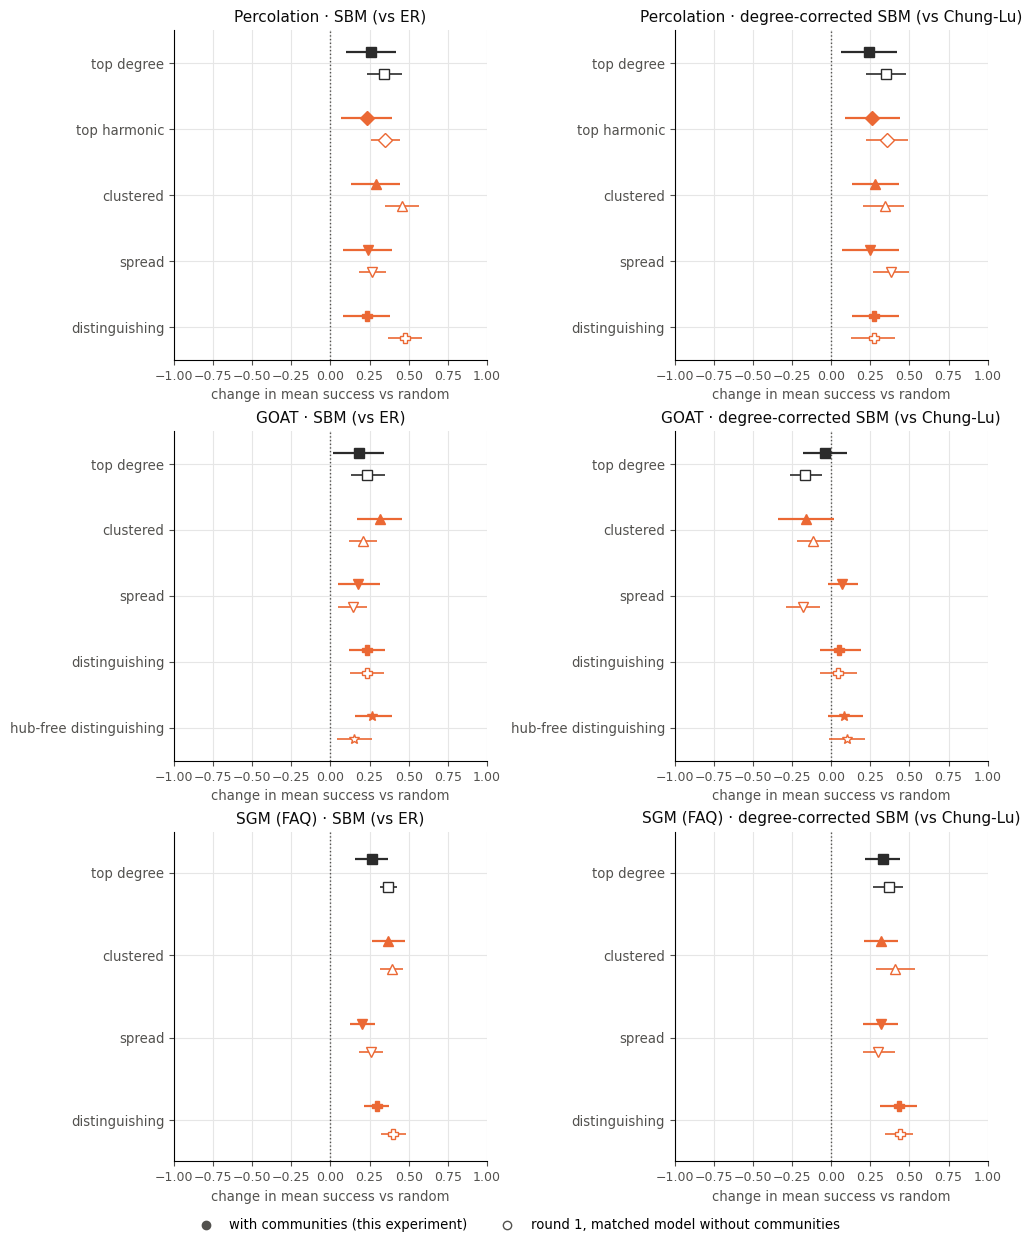

with communities: change vs random  \
algorithm   setting              rule                                                         
Percolation SBM                  top degree                            +0.26 [+0.10, +0.42]   
                                 top harmonic                          +0.23 [+0.07, +0.39]   
                                 clustered                             +0.29 [+0.13, +0.44]   
                                 spread                                +0.24 [+0.08, +0.39]   
                                 distinguishing                        +0.23 [+0.08, +0.38]   
            degree-corrected SBM top degree                            +0.24 [+0.06, +0.42]   
                                 top harmonic                          +0.26 [+0.09, +0.44]   
                                 clustered                             +0.28 [+0.13, +0.43]   
                                 spread                                +0.25 [+0.07, +0.43]   
                                 distinguishing                        +0.27 [+0.13, +0.43]   
GOAT        SBM                  top degree                            +0.18 [+0.02, +0.34]   
                                 clustered                             +0.32 [+0.17, +0.46]   
                                 spread                                +0.18 [+0.05, +0.32]   
                                 distinguishing                        +0.23 [+0.12, +0.35]   
                                 hub-free distinguishing               +0.27 [+0.16, +0.39]   
            degree-corrected SBM top degree                            -0.04 [-0.18, +0.10]   
                                 clustered                             -0.16 [-0.34, +0.02]   
                                 spread                                +0.07 [-0.02, +0.17]   
                                 distinguishing                        +0.05 [-0.07, +0.19]   
                                 hub-free distinguishing               +0.08 [-0.02, +0.20]   
SGM (FAQ)   SBM                  top degree                            +0.27 [+0.16, +0.37]   
                                 clustered                             +0.37 [+0.27, +0.48]   
                                 spread                                +0.20 [+0.12, +0.28]   
                                 distinguishing                        +0.30 [+0.22, +0.38]   
            degree-corrected SBM top degree                            +0.33 [+0.22, +0.44]   
                                 clustered                             +0.32 [+0.21, +0.42]   
                                 spread                                +0.32 [+0.20, +0.42]   
                                 distinguishing                        +0.43 [+0.31, +0.55]   

                                                         round 1 (ER): change vs random  \
algorithm   setting              rule                                                     
Percolation SBM                  top degree                        +0.34 [+0.23, +0.46]   
                                 top harmonic                      +0.35 [+0.26, +0.44]   
                                 clustered                         +0.46 [+0.35, +0.57]   
                                 spread                            +0.27 [+0.18, +0.36]   
                                 distinguishing                    +0.47 [+0.37, +0.58]   
            degree-corrected SBM top degree                                         NaN   
                                 top harmonic                                       NaN   
                                 clustered                                          NaN   
                                 spread                                             NaN   
                                 distinguishing                                     NaN   
GOAT        SBM                  top degree                        +0.23 [+0.13, +0.35]   
                       

with communities: change vs top degree  \
algorithm   setting              rule                                                             
Percolation SBM                  top harmonic                              -0.03 [-0.10, +0.05]   
                                 clustered                                 +0.03 [-0.05, +0.12]   
                                 spread                                    -0.02 [-0.12, +0.08]   
                                 distinguishing                            -0.03 [-0.15, +0.09]   
            degree-corrected SBM top harmonic                              +0.02 [-0.03, +0.07]   
                                 clustered                                 +0.04 [-0.06, +0.14]   
                                 spread                                    +0.01 [-0.07, +0.08]   
                                 distinguishing                            +0.03 [-0.03, +0.09]   
GOAT        SBM                  clustered                                 +0.13 [+0.01, +0.24]   
                                 spread                                    -0.01 [-0.09, +0.07]   
                                 distinguishing                            +0.05 [-0.08, +0.18]   
                                 hub-free distinguishing                   +0.08 [-0.05, +0.20]   
            degree-corrected SBM clustered                                 -0.12 [-0.23, -0.01]   
                                 spread                                    +0.11 [+0.03, +0.20]   
                                 distinguishing                            +0.09 [+0.03, +0.17]   
                                 hub-free distinguishing                   +0.12 [+0.04, +0.24]   
SGM (FAQ)   SBM                  clustered                                 +0.10 [+0.02, +0.18]   
                                 spread                                    -0.07 [-0.14, +0.02]   
                                 distinguishing                            +0.03 [-0.03, +0.11]   
            degree-corrected SBM clustered                                 -0.02 [-0.11, +0.08]   
                                 spread                                    -0.02 [-0.10, +0.07]   
                                 distinguishing                            +0.10 [+0.03, +0.18]   

                                                         round 1 (ER): change vs top degree  \
algorithm   setting              rule                                                         
Percolation SBM                  top harmonic                          +0.01 [-0.10, +0.11]   
                                 clustered                             +0.12 [-0.02, +0.26]   
                                 spread                                -0.07 [-0.17, +0.03]   
                                 distinguishing                        +0.13 [+0.04, +0.24]   
            degree-corrected SBM top harmonic                                           NaN   
                                 clustered                                              NaN   
                                 spread                                                 NaN   
                                 distinguishing                                         NaN   
GOAT        SBM                  clustered                             -0.03 [-0.13, +0.09]   
                                 spread                                -0.09 [-0.17, -0.01]   
                                 distinguishing                        +0.00 [-0.09, +0.09]   
                                 hub-free distinguishing               -0.08 [-0.21, +0.04]   
            degree-corrected SBM clustered                                              NaN   
                                 spread                                                 NaN   
                                 distinguishing                                         NaN   
                                 hub-free distinguishing         

In [7]:
round1 = SR.round1_evaluations()
effect = SR.community_effect(ev, round1)
SR.plot_community_effect(effect)
plt.show()
display(SR.show_community_effect(effect))
display(SR.show_community_effect(SR.community_effect(ev, round1, against='top_degree'), against='top_degree'))

## 6. Where the seeds land

For each rule, averaged over pairs and budgets:
- **Blocks covered:** how many of the 4 blocks hold at least one seed.
- **Sets covering every block:** the share of the rule's sets with a seed in every block.
- **Largest block's share of seeds:** 0.25 means the seeds are spread evenly; 1 means they all sit in one block.

Rules that concentrate their seeds, such as clustered, may succeed inside one community and fail to cross to the others (only 20% of edges run between blocks). Comparing a rule's coverage with its success here shows whether that happens.

In [8]:
display(SR.coverage_table(ev))

blocks covered (of 4)  \
algorithm   setting              rule                                                      
Percolation SBM                  random                                             3.27   
                                 top degree                                         3.17   
                                 top harmonic                                       3.25   
                                 clustered                                          1.99   
                                 spread                                             3.60   
                                 distinguishing                                     3.08   
                                 top degree by block                                3.83   
                                 best of 1,000 (averaged weights)                   2.33   
                                 best of 1,000 by degree                            3.14   
            degree-corrected SBM random                                             2.72   
                                 top degree                                         2.74   
                                 top harmonic                                       2.72   
                                 clustered                                          1.66   
                                 spread                                             3.20   
                                 distinguishing                                     2.96   
                                 top degree by block                                3.40   
                                 best of 1,000 (averaged weights)                   1.86   
                                 best of 1,000 by degree                            2.71   
GOAT        SBM                  random                                             3.72   
                                 top degree                                         3.70   
                                 clustered                                          2.17   
                                 spread                                             3.96   
                                 distinguishing                                     3.61   
                                 top degree by block                                4.00   
                                 best of 1,000 (averaged weights)                   3.24   
                                 best of 1,000 by degree                            3.69   
                                 hub-free distinguishing                            3.61   
            degree-corrected SBM random                                             2.62   
                                 top degree                                         2.51   
                                 clustered                                          1.53   
                                 spread                                             3.23   
                                 distinguishing                                     2.97   
                                 top degree by block                                3.40   
                                 best of 1,000 (averaged weights)                   2.07   
                                 best of 1,000 by degree                            2.70   
                                 hub-free distinguishing                            2.82   
SGM (FAQ)   SBM                  random                                             4.00   
                                 top degree                                         3.98   
                                 clustered                                          2.65   
                                 spread                                             4.00   
                                 distinguishing                                     4.00   
                                 top degree by block                                4.00   
                   